## Assignment no 14

## PCA and K-Means Clustering on the Wine Dataset

## Task 1: Exploratory Data Analysis (EDA):

In [1]:
# Install required libraries if not already installed
# Uncomment the following line if required:
# !pip install numpy pandas matplotlib seaborn scikit-learn

# Import numerical libraries
import numpy as np
import pandas as pd

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import dataset
from sklearn.datasets import load_wine

# Import preprocessing
from sklearn.preprocessing import StandardScaler

# Import dimensionality reduction
from sklearn.decomposition import PCA

# Import clustering
from sklearn.cluster import KMeans

# Import evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_theme(style="whitegrid")

# Set figure size
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the Wine dataset
wine = load_wine()

# Create DataFrame containing the 13 input features
df = pd.DataFrame(
    wine.data,
    columns=[
        "Alcohol",
        "Malic",
        "Ash",
        "Alcalinity",
        "Magnesium",
        "Phenols",
        "Flavanoids",
        "Nonflavanoids",
        "Proanthocyanins",
        "Color",
        "Hue",
        "Dilution",
        "Proline"
    ]
)

# Add actual wine class as Type
# Convert target from 0, 1, 2 to 1, 2, 3
df.insert(0, "Type", wine.target + 1)

# Display first five records
print("First five records:")
display(df.head())

# Display dataset dimensions
print("\nDataset Shape:", df.shape)

# Display dataset information
print("\nDataset Information:")
df.info()

First five records:


,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,1,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Dataset Shape: (178, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Type             178 non-null    int32  
 1   Alcohol          178 non-null    float64
 2   Malic            178 non-null    float64
 3   Ash              178 non-null    float64
 4   Alcalinity       178 non-null    float64
 5   Magnesium        178 non-null    float64
 6   Phenols          178 non-null    float64
 7   Flavanoids       178 non-null    float64
 8   Nonflavanoids    178 non-null    float64
 9   Proanthocyanins  178 non-null    float64
 10  Color            178 non-null    float64
 11  Hue              178 non-null    float64
 12  Dilution         178 non-null    float64
 13  Proline          178 non-null    float64
dtypes: float64(13), int32(1)
memory usage: 18.9 KB


In [3]:
# Display first five rows
display(df.head())

# Display last five rows
display(df.tail())

# Check dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Statistical summary
print("\nStatistical Summary:")
display(df.describe().T)

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check unique wine classes
print("\nWine Classes:")
print(df["Type"].unique())

# Distribution of wine classes
print("\nClass Distribution:")
print(df["Type"].value_counts().sort_index())

,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,1,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,Type,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
173,3,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.7,0.64,1.74,740.0
174,3,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.3,0.70,1.56,750.0
175,3,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.2,0.59,1.56,835.0
176,3,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.3,0.60,1.62,840.0
177,3,14.13,4.10,2.74,24.5,96.0,2.05,0.76,0.56,1.35,9.2,0.61,1.60,560.0


Number of Rows: 178
Number of Columns: 14

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
Type,178.0,1.938202,0.775035,1.00,1.0000,2.000,3.0000,3.00
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Alcalinity,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoids,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58



Data Types:
Type                 int32
Alcohol            float64
Malic              float64
Ash                float64
Alcalinity         float64
Magnesium          float64
Phenols            float64
Flavanoids         float64
Nonflavanoids      float64
Proanthocyanins    float64
Color              float64
Hue                float64
Dilution           float64
Proline            float64
dtype: object

Missing Values:
Type               0
Alcohol            0
Malic              0
Ash                0
Alcalinity         0
Magnesium          0
Phenols            0
Flavanoids         0
Nonflavanoids      0
Proanthocyanins    0
Color              0
Hue                0
Dilution           0
Proline            0
dtype: int64

Duplicate Records: 0

Wine Classes:
[1 2 3]

Class Distribution:
Type
1    59
2    71
3    48
Name: count, dtype: int64


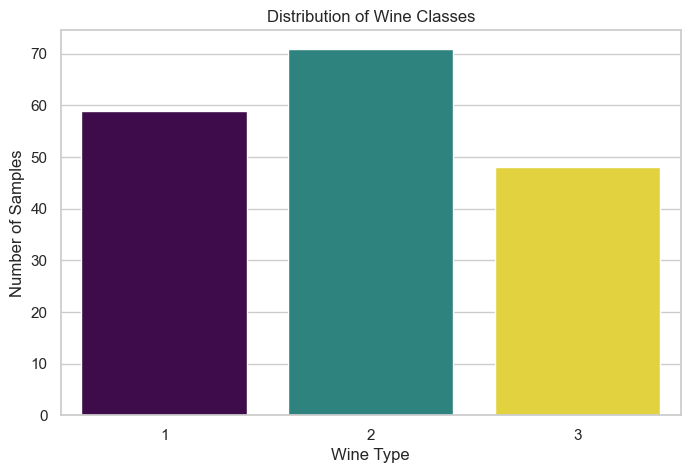

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Type",
    hue="Type",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Wine Classes")
plt.xlabel("Wine Type")
plt.ylabel("Number of Samples")

plt.show()

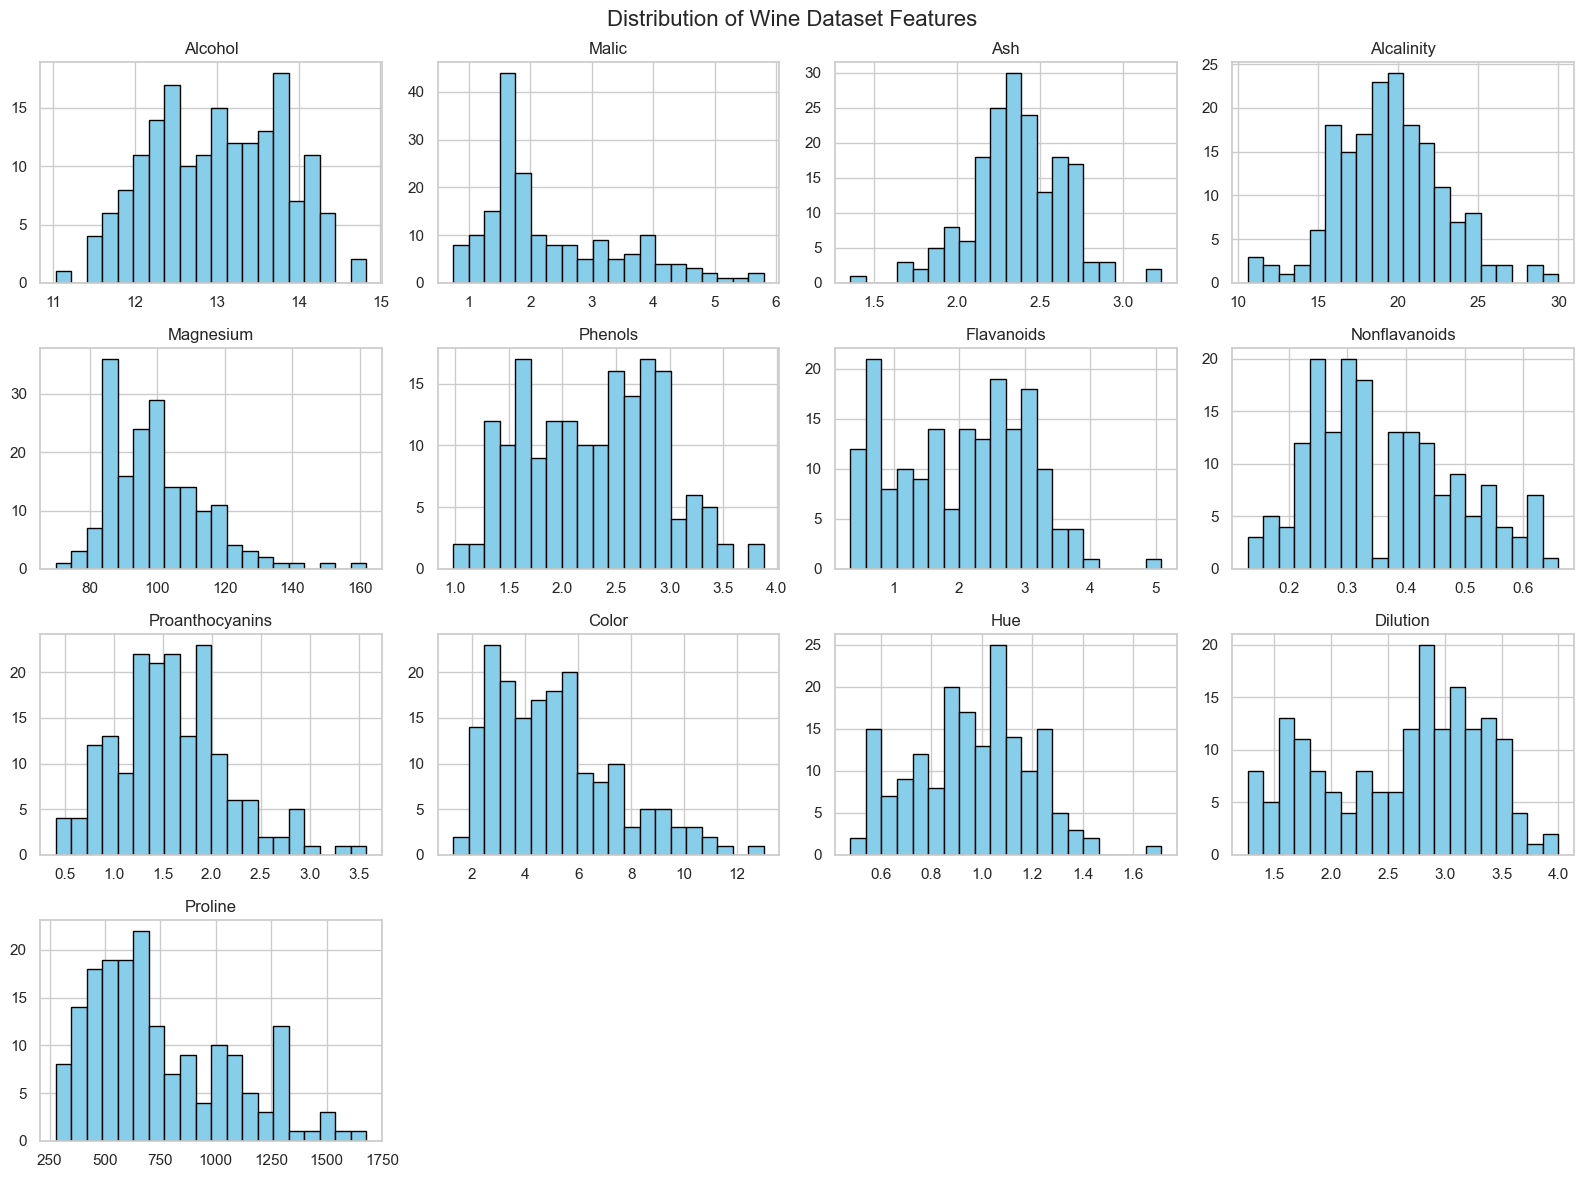

In [5]:
# Select the 13 numerical features
features = df.drop(columns=["Type"])

# Create histograms
features.hist(
    figsize=(16, 12),
    bins=20,
    color="skyblue",
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Wine Dataset Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

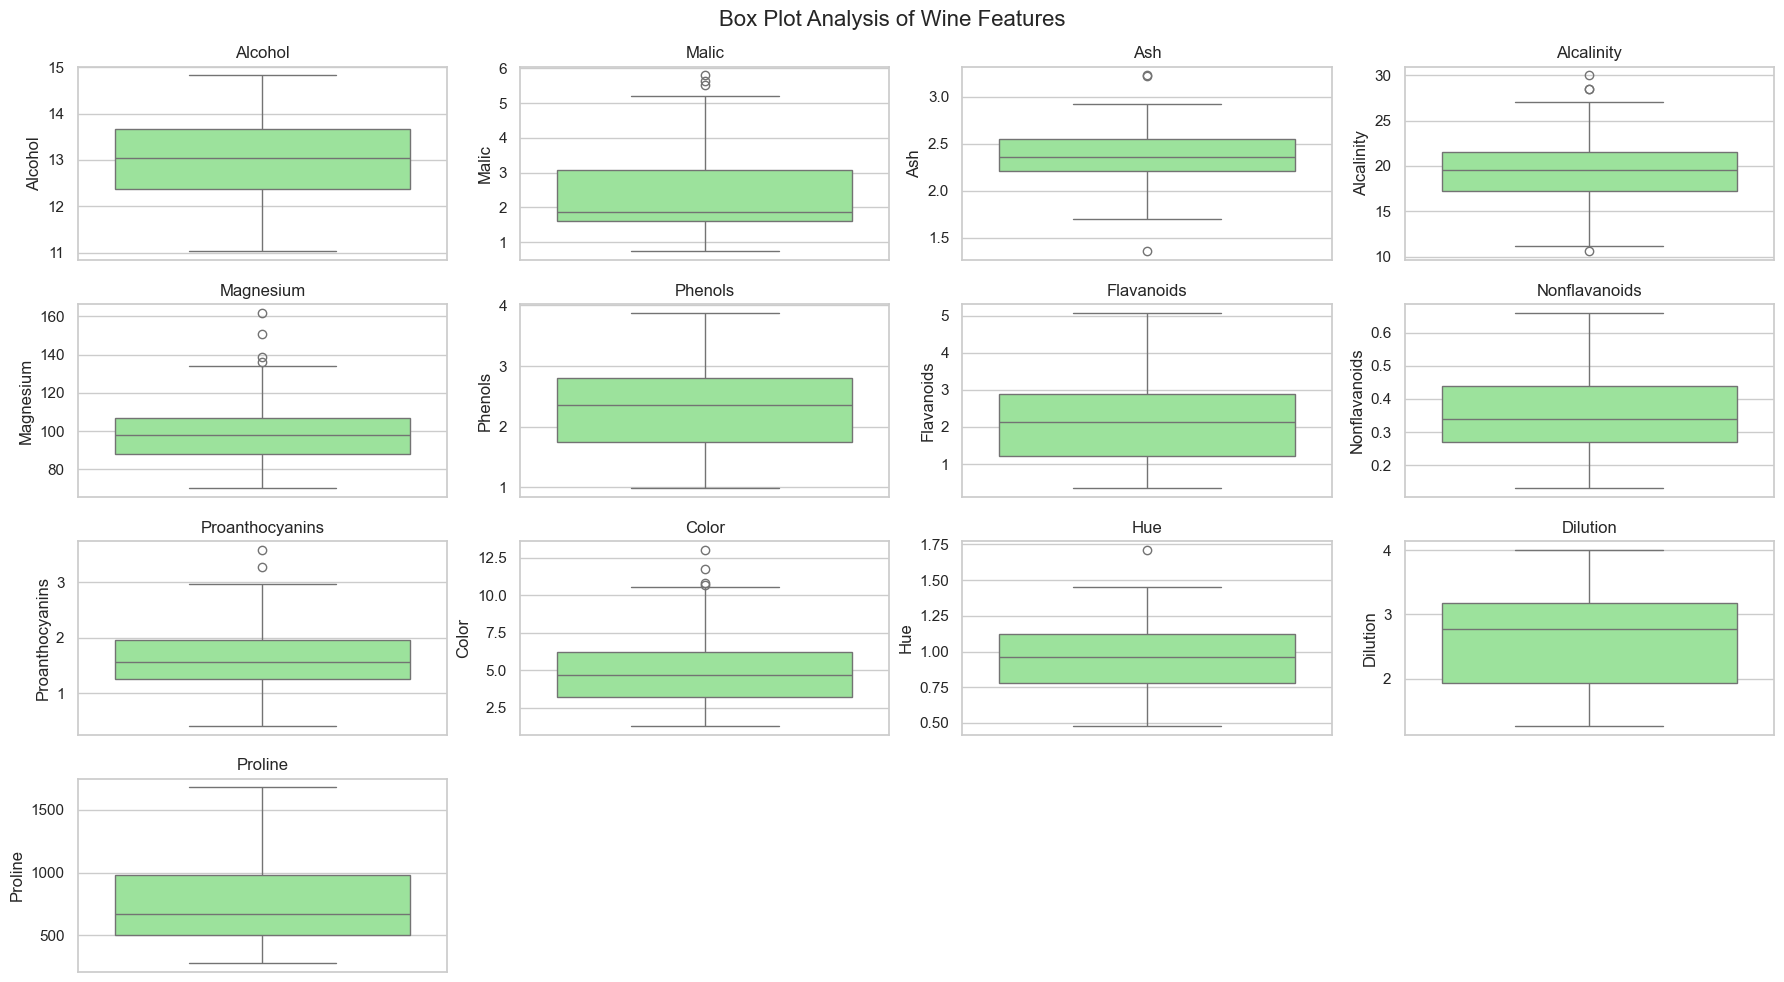

In [6]:
plt.figure(figsize=(18, 10))

for i, column in enumerate(features.columns, 1):

    plt.subplot(4, 4, i)

    sns.boxplot(
        y=df[column],
        color="lightgreen"
    )

    plt.title(column)

plt.suptitle(
    "Box Plot Analysis of Wine Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

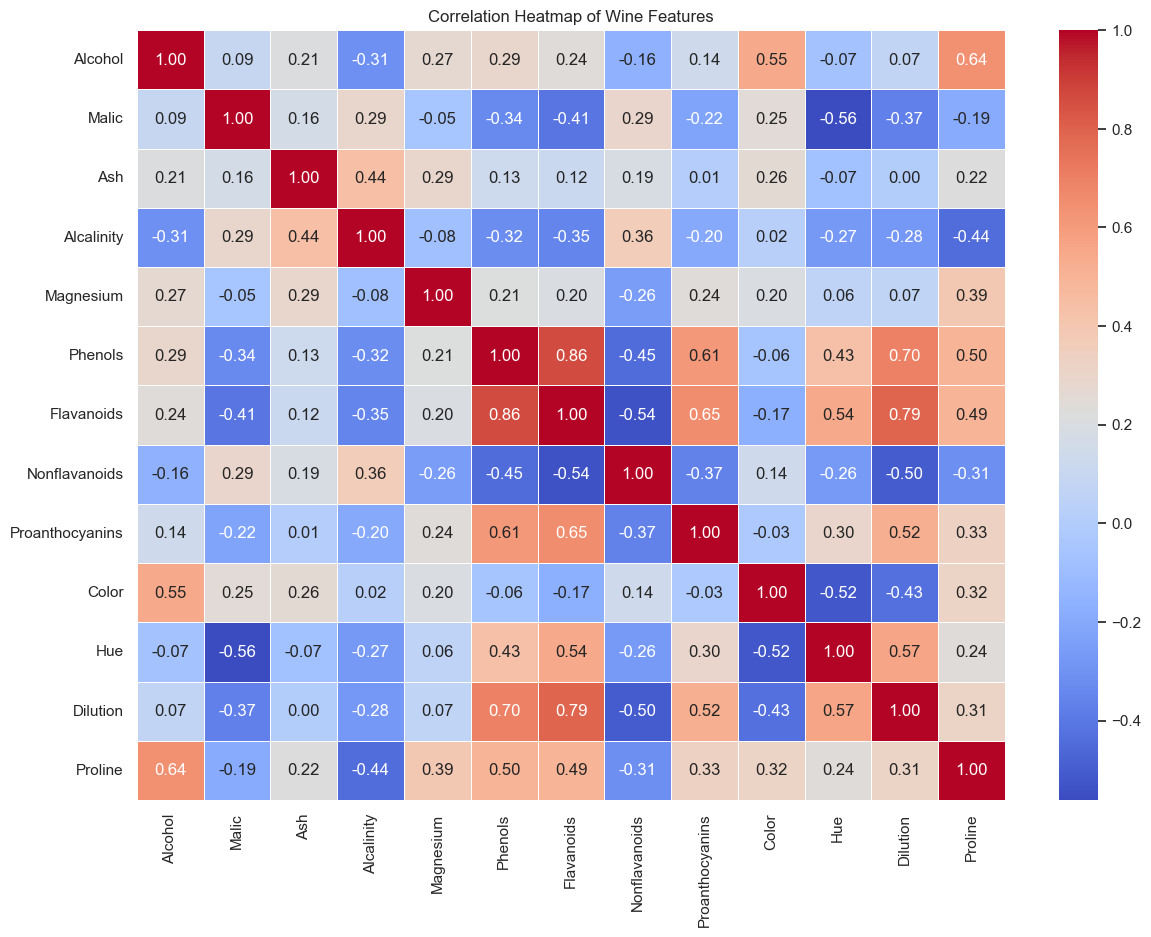

In [7]:
# Calculate correlation matrix
correlation_matrix = features.corr()

# Plot correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Wine Features")

plt.show()

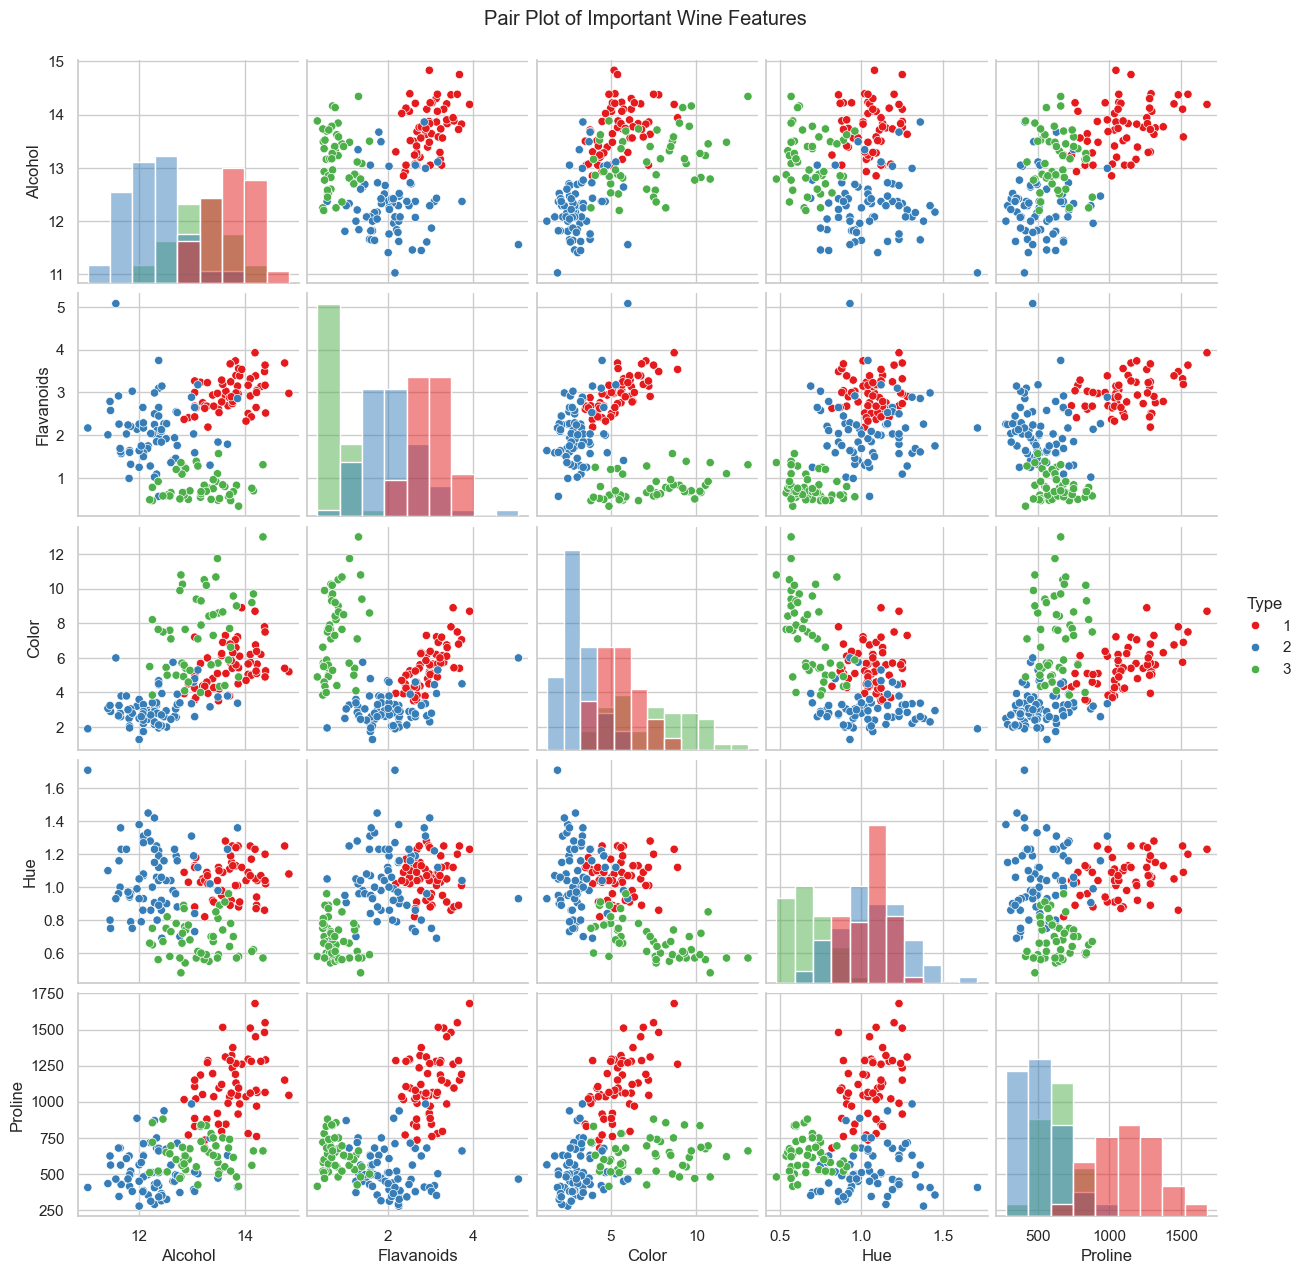

In [8]:
# Pair plot for selected important features
selected_features = [
    "Alcohol",
    "Flavanoids",
    "Color",
    "Hue",
    "Proline",
    "Type"
]

sns.pairplot(
    df[selected_features],
    hue="Type",
    diag_kind="hist",
    palette="Set1"
)

plt.suptitle(
    "Pair Plot of Important Wine Features",
    y=1.02
)

plt.show()

In [9]:
# Separate independent features
X = df.drop(columns=["Type"])

# Store actual wine classes for later evaluation
y = df["Type"]

# Create StandardScaler object
scaler = StandardScaler()

# Standardize all 13 features
X_scaled = scaler.fit_transform(X)

# Convert standardized data into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

# Display standardized data
print("Standardized Dataset:")
display(X_scaled_df.head())

# Verify mean and standard deviation
print("\nFeature Means:")
print(X_scaled_df.mean().round(2))

print("\nFeature Standard Deviations:")
print(X_scaled_df.std(ddof=0).round(2))

Standardized Dataset:


,Alcohol,Malic,Ash,Alcalinity,Magnesium,Phenols,Flavanoids,Nonflavanoids,Proanthocyanins,Color,Hue,Dilution,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874



Feature Means:
Alcohol            0.0
Malic              0.0
Ash               -0.0
Alcalinity        -0.0
Magnesium         -0.0
Phenols           -0.0
Flavanoids         0.0
Nonflavanoids     -0.0
Proanthocyanins   -0.0
Color             -0.0
Hue                0.0
Dilution           0.0
Proline           -0.0
dtype: float64

Feature Standard Deviations:
Alcohol            1.0
Malic              1.0
Ash                1.0
Alcalinity         1.0
Magnesium          1.0
Phenols            1.0
Flavanoids         1.0
Nonflavanoids      1.0
Proanthocyanins    1.0
Color              1.0
Hue                1.0
Dilution           1.0
Proline            1.0
dtype: float64


## Task 2: Dimensionality Reduction with PCA:

Apply PCA

In [10]:
# Create PCA object
# None means calculate all available principal components
pca = PCA()

# Fit PCA and transform standardized data
X_pca = pca.fit_transform(X_scaled)

# Display explained variance ratio
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print("\nCumulative Explained Variance:")
print(cumulative_variance)

Explained Variance Ratio:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Cumulative Explained Variance:
[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


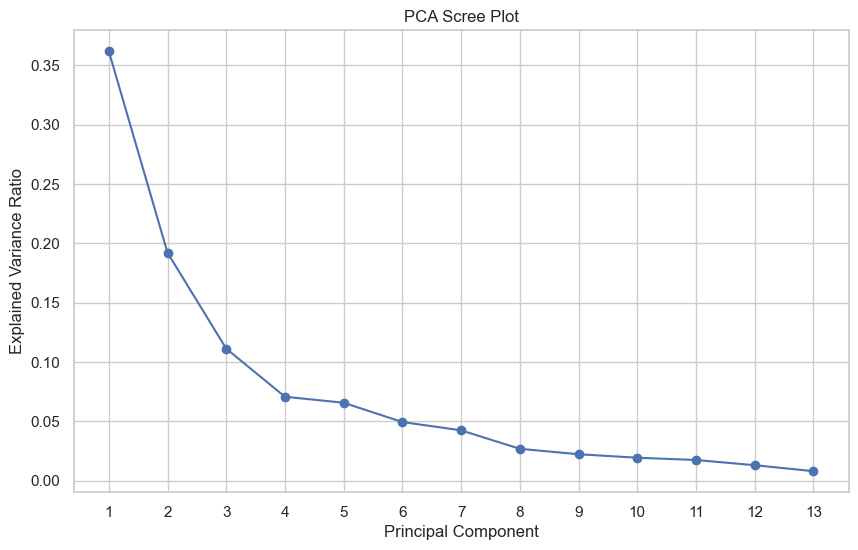

In [11]:
##SCREE PLOT
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker="o",
    linestyle="-"
)

plt.title("PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.xticks(range(1, 14))
plt.grid(True)

plt.show()

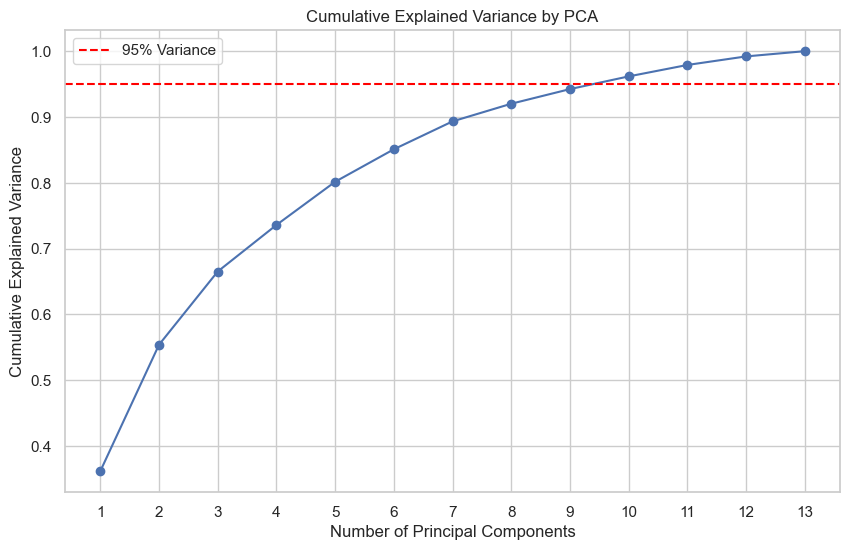

In [12]:
##Cumulative explained variance plot
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, 14),
    cumulative_variance,
    marker="o"
)

# Draw 95% variance threshold
plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% Variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("Cumulative Explained Variance by PCA")

plt.xticks(range(1, 14))
plt.legend()
plt.grid(True)

plt.show()


Determine optimal number of components

In [13]:
# Find the number of components required
n_components = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Optimal Number of Principal Components:",
    n_components
)

print(
    "Total Variance Explained:",
    round(cumulative_variance[n_components - 1] * 100, 2),
    "%"
)

Optimal Number of Principal Components: 10
Total Variance Explained: 96.17 %


Transform dataset using selected components

In [14]:
# Create PCA with selected number of components
pca_final = PCA(n_components=n_components)

# Transform standardized dataset
X_pca_final = pca_final.fit_transform(X_scaled)

# Create PCA DataFrame
pca_columns = [
    f"PC{i+1}"
    for i in range(n_components)
]

pca_df = pd.DataFrame(
    X_pca_final,
    columns=pca_columns
)

# Display transformed data
print("PCA Transformed Dataset:")
display(pca_df.head())

print("\nOriginal Shape:", X_scaled.shape)
print("PCA Shape:", X_pca_final.shape)

print(
    "\nVariance Retained:",
    round(
        sum(pca_final.explained_variance_ratio_) * 100,
        2
    ),
    "%"
)

PCA Transformed Dataset:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956
1,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701
2,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361
3,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413
4,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366



Original Shape: (178, 13)
PCA Shape: (178, 10)

Variance Retained: 96.17 %


## Task 3: Clustering with Original Data:

Clustering using original standardized data

In [15]:
# Create K-Means model
kmeans_original = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

# Fit model and predict cluster labels
original_clusters = kmeans_original.fit_predict(
    X_scaled
)

# Add cluster labels to original DataFrame
df["Original_Cluster"] = original_clusters

# Display cluster distribution
print("Original Data Cluster Distribution:")
print(df["Original_Cluster"].value_counts().sort_index())

Original Data Cluster Distribution:
Original_Cluster
0    65
1    51
2    62
Name: count, dtype: int64


  File "c:\Users\yashr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Visualize original data clustering

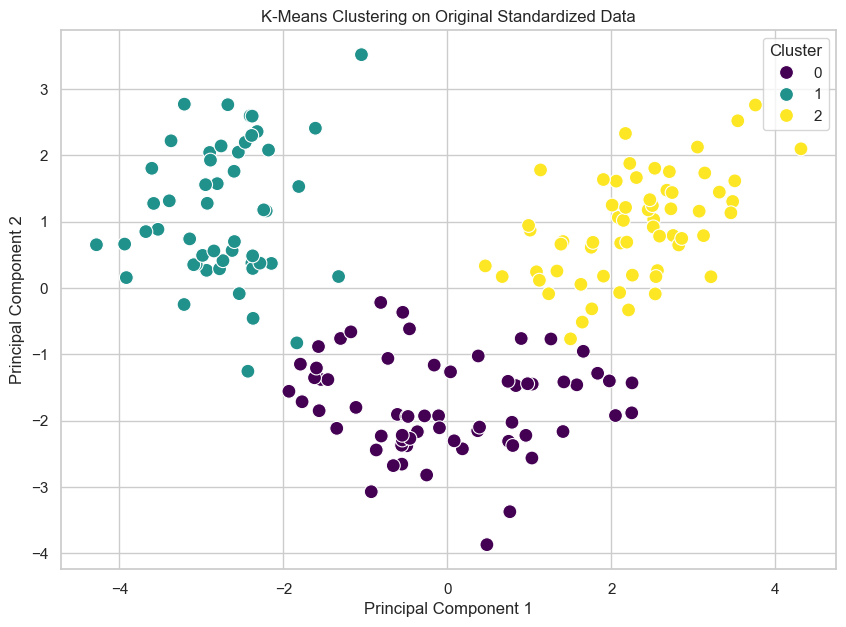

In [16]:
# Create visualization DataFrame
original_plot = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": original_clusters
})

# Plot clustering results
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=original_plot,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title(
    "K-Means Clustering on Original Standardized Data"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")
plt.show()

Evaluate original data clustering

In [17]:
# Evaluate original clustering
original_silhouette = silhouette_score(
    X_scaled,
    original_clusters
)

original_db = davies_bouldin_score(
    X_scaled,
    original_clusters
)

original_ari = adjusted_rand_score(
    y,
    original_clusters
)

print("ORIGINAL DATA CLUSTERING RESULTS")
print("--------------------------------")

print(
    "Silhouette Score:",
    round(original_silhouette, 4)
)

print(
    "Davies-Bouldin Index:",
    round(original_db, 4)
)

print(
    "Adjusted Rand Index:",
    round(original_ari, 4)
)

ORIGINAL DATA CLUSTERING RESULTS
--------------------------------
Silhouette Score: 0.2849
Davies-Bouldin Index: 1.3892
Adjusted Rand Index: 0.8975


## Task 4: Clustering with PCA Data:

Clustering using PCA-transformed data

In [18]:
# Create K-Means model for PCA data
kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

# Fit model and predict clusters
pca_clusters = kmeans_pca.fit_predict(
    X_pca_final
)

# Add cluster labels to PCA DataFrame
pca_df["PCA_Cluster"] = pca_clusters

# Display cluster distribution
print("PCA Data Cluster Distribution:")
print(pca_df["PCA_Cluster"].value_counts().sort_index())

PCA Data Cluster Distribution:
PCA_Cluster
0    65
1    51
2    62
Name: count, dtype: int64


Visualize PCA clustering

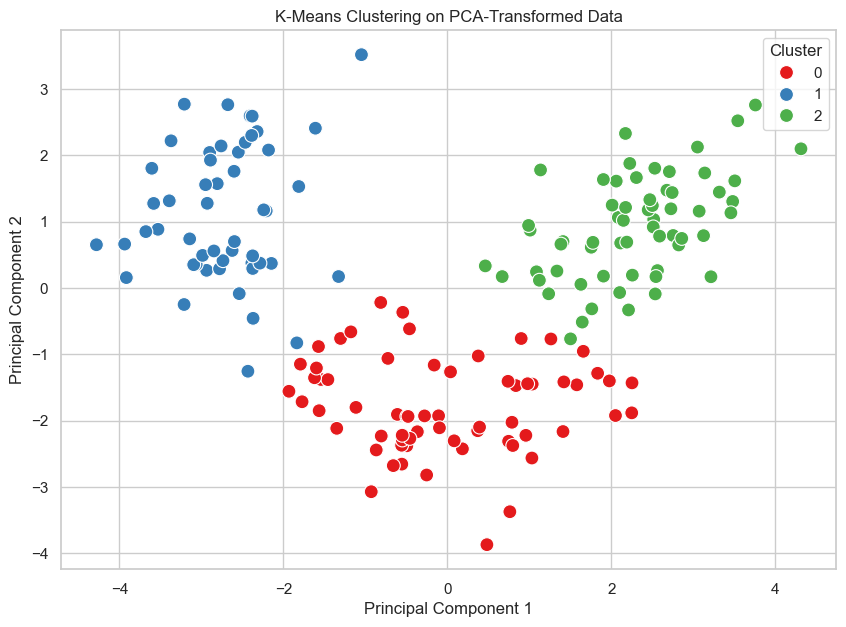

In [19]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca_final[:, 0],
    y=X_pca_final[:, 1],
    hue=pca_clusters,
    palette="Set1",
    s=100
)

plt.title(
    "K-Means Clustering on PCA-Transformed Data"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")
plt.show()

Evaluate PCA clustering

In [20]:
# Calculate evaluation metrics
pca_silhouette = silhouette_score(
    X_pca_final,
    pca_clusters
)

pca_db = davies_bouldin_score(
    X_pca_final,
    pca_clusters
)

pca_ari = adjusted_rand_score(
    y,
    pca_clusters
)

print("PCA DATA CLUSTERING RESULTS")
print("---------------------------")

print(
    "Silhouette Score:",
    round(pca_silhouette, 4)
)

print(
    "Davies-Bouldin Index:",
    round(pca_db, 4)
)

print(
    "Adjusted Rand Index:",
    round(pca_ari, 4)
)

PCA DATA CLUSTERING RESULTS
---------------------------
Silhouette Score: 0.2987
Davies-Bouldin Index: 1.3363
Adjusted Rand Index: 0.8975


## Task 5: Comparison and Analysis:

In [21]:
# Create comparison DataFrame
comparison = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Adjusted Rand Index"
    ],

    "Original Data": [
        original_silhouette,
        original_db,
        original_ari
    ],

    "PCA Data": [
        pca_silhouette,
        pca_db,
        pca_ari
    ]
})

print("CLUSTERING PERFORMANCE COMPARISON")

display(
    comparison.round(4)
)

CLUSTERING PERFORMANCE COMPARISON


,Metric,Original Data,PCA Data
0,Silhouette Score,0.2849,0.2987
1,Davies-Bouldin Index,1.3892,1.3363
2,Adjusted Rand Index,0.8975,0.8975


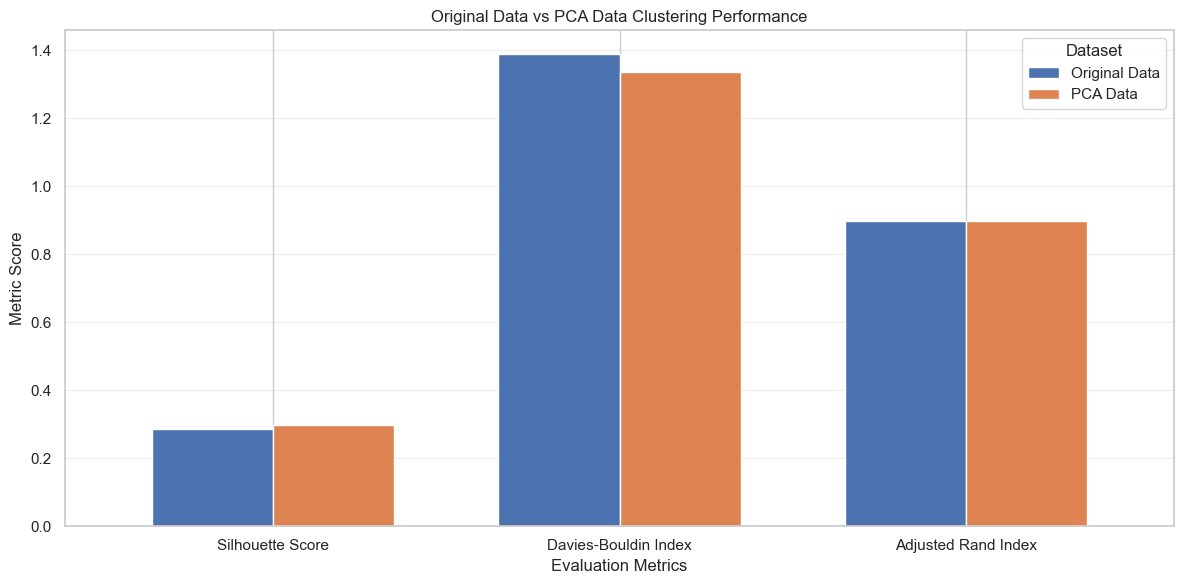

In [22]:
# Plot comparison of clustering metrics
comparison_plot = comparison.set_index(
    "Metric"
)

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.7
)

plt.title(
    "Original Data vs PCA Data Clustering Performance"
)

plt.ylabel("Metric Score")
plt.xlabel("Evaluation Metrics")

plt.xticks(rotation=0)
plt.legend(title="Dataset")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [23]:
# Compare actual classes and original clusters
print("Original Data Cluster vs Actual Wine Type")

original_cross = pd.crosstab(
    y,
    original_clusters,
    rownames=["Actual Wine Type"],
    colnames=["Predicted Cluster"]
)

display(original_cross)

# Compare actual classes and PCA clusters
print("PCA Cluster vs Actual Wine Type")

pca_cross = pd.crosstab(
    y,
    pca_clusters,
    rownames=["Actual Wine Type"],
    colnames=["Predicted Cluster"]
)

display(pca_cross)

Original Data Cluster vs Actual Wine Type


Predicted Cluster,0,1,2
Actual Wine Type,,,
1,0,0,59
2,65,3,3
3,0,48,0


PCA Cluster vs Actual Wine Type


Predicted Cluster,0,1,2
Actual Wine Type,,,
1,0,0,59
2,65,3,3
3,0,48,0


## Task 6: Conclusion and Insights

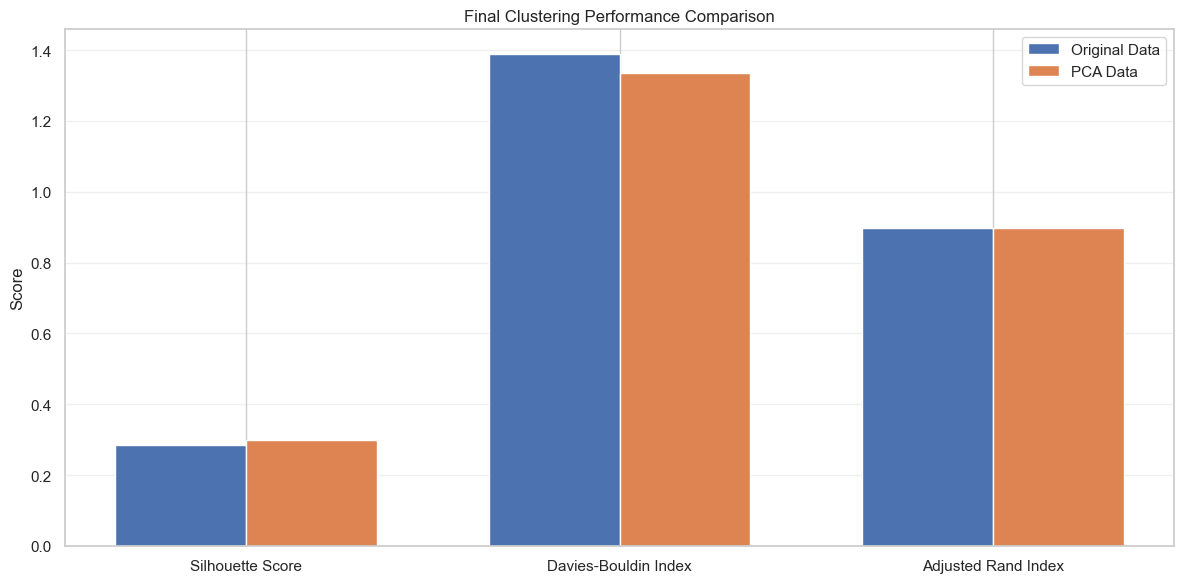

In [24]:
# Create final comparison chart
metrics = [
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Adjusted Rand Index"
]

original_scores = [
    original_silhouette,
    original_db,
    original_ari
]

pca_scores = [
    pca_silhouette,
    pca_db,
    pca_ari
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    original_scores,
    width,
    label="Original Data"
)

plt.bar(
    x + width/2,
    pca_scores,
    width,
    label="PCA Data"
)

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Final Clustering Performance Comparison")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()